In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

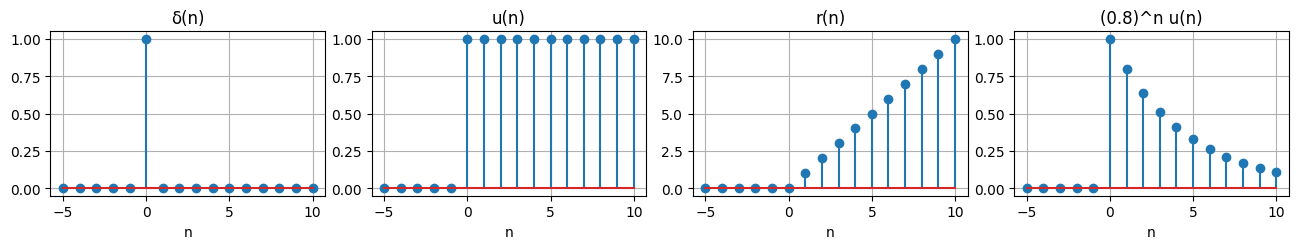

In [4]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)  # unit impulse
step = (n >= 0).astype(float)   # unit step
ramp = n * step                 # unit ramp
expo = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.grid(True)

plt.tight_layout()
plt.show()

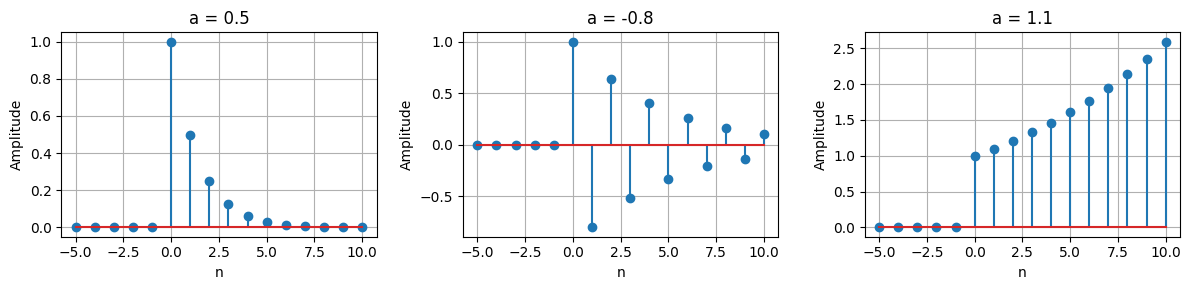

In [5]:
n = np.arange(-5, 11)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, a_values):
    x = (a ** n) * (n >= 0)
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

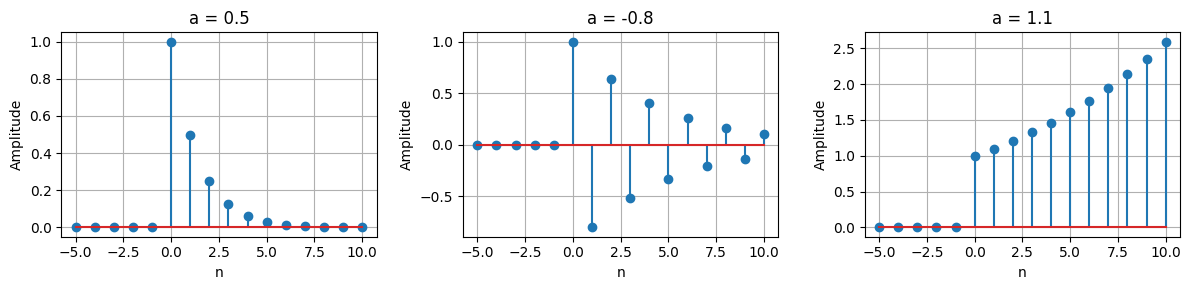

In [6]:
n = np.arange(-5, 11)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, a_values):
    x = (a ** n) * (n >= 0)
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [8]:
import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))

    t = np.arange(len(x)) / fs

    print(f"fs = {fs} Hz")
    print(f"duration = {len(x)/fs:.2f} s")
    print(f"samples = {len(x)}")

    plt.plot(t, x)
    plt.xlabel("time (s)")
    plt.ylabel("amplitude")
    plt.title("My recording")
    plt.show()
else:
    print("Audio file not found")


Audio file not found


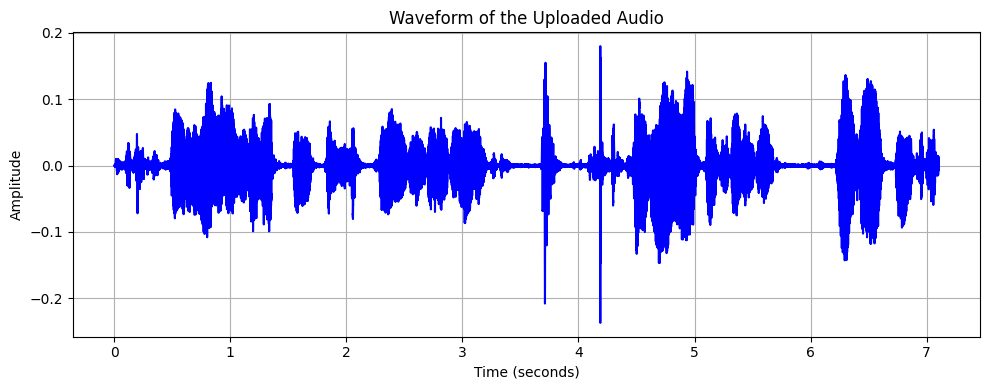

In [7]:
from IPython.display import Audio, display
import matplotlib.pyplot as plt
import numpy as np

# Create a time array in seconds
t = np.arange(len(audio)) / fs

# Plot the waveform
plt.figure(figsize=(10, 4))
plt.plot(t, audio, color='b')
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform of the Uploaded Audio")
plt.grid(True)
plt.tight_layout()
plt.show()

# Provide audio playback widget
display(Audio(audio, rate=fs))

In [11]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [16]:
from google.colab import files

uploaded = files.upload()

Saving Record (online-voice-recorder.com).mp3 to Record (online-voice-recorder.com) (1).mp3


In [20]:
print(type(uploaded))
print(uploaded.keys())


<class 'dict'>
dict_keys(['Record (online-voice-recorder.com) (1).mp3'])


In [6]:
import librosa
import numpy as np

filename = list(uploaded.keys())[0]

# Load the mp3 file (librosa automatically converts and decodes it)
audio, fs = librosa.load(filename, sr=None)

print("Audio loaded successfully!")
print("Sampling rate (fs):", fs, "Hz")
print("Audio shape:", audio.shape)
print("Duration:", len(audio)/fs, "seconds")

Audio loaded successfully!
Sampling rate (fs): 48000 Hz
Audio shape: (340992,)
Duration: 7.104 seconds


In [5]:
from google.colab import files
import os

print("Please upload your audio file (.mp3 or .wav):")
uploaded = files.upload()

if uploaded:
    filename = list(uploaded.keys())[0]
    print("\nFile uploaded successfully:", filename)
    print("File extension:", os.path.splitext(filename)[1])
    print("File size:", os.path.getsize(filename), "bytes")
else:
    print("No file was uploaded.")

Please upload your audio file (.mp3 or .wav):


Saving Record (online-voice-recorder.com).mp3 to Record (online-voice-recorder.com).mp3

File uploaded successfully: Record (online-voice-recorder.com).mp3
File extension: .mp3
File size: 227328 bytes


### Task 1.4: Spectral Analysis (Spectrogram) of the Audio Signal

In this task, we will analyze the frequency content of your uploaded audio recording over time by computing and plotting its Short-Time Fourier Transform (STFT) spectrogram.

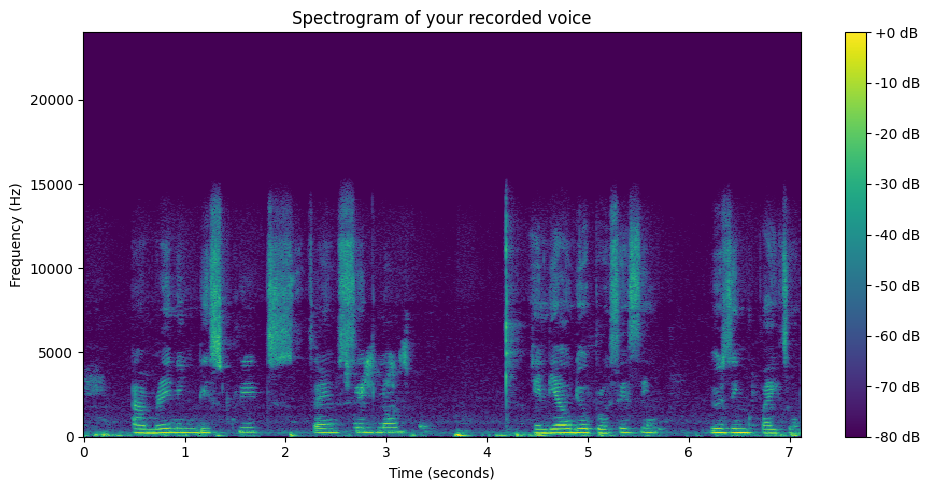

In [8]:
import librosa.display

# Compute short-time Fourier transform (STFT)
D = librosa.stft(audio)
# Convert amplitude to decibels (dB)
DB = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# Plot the spectrogram
plt.figure(figsize=(10, 5))
librosa.display.specshow(DB, sr=fs, x_axis='time', y_axis='hz', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram of your recorded voice")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

## Analysis Questions – Answers

### 1. What is the sampling rate of your phone recording?

From the Colab cell that loaded the uploaded MP3 with `librosa.load(filename, sr=None)`, the native sampling rate was printed as:

```
Sampling rate (fs): 48000 Hz
Audio shape: (340992,)
Duration: 7.104 seconds
```

So **fs = 48,000 samples/second = 48 kHz** (sampling interval Ts = 1/48000 ≈ 20.83 µs). The number of samples checks out: 340,992 / 48,000 = 7.104 s.

### 2. How many numbers are needed to store one minute of it in mono?

For a mono (one-channel) signal the number of samples is:

```
N = fs × duration = 48,000 samples/s × 60 s = 2,880,000 samples
```

So **2,880,000 numbers** are needed for one minute of mono audio.

Storage depends on how each number is represented:
- 16-bit PCM (standard WAV, 2 bytes/sample): 2,880,000 × 2 = **5,760,000 bytes ≈ 5.76 MB** (5.49 MiB)
- 32-bit float (as returned by `librosa`, 4 bytes/sample): 2,880,000 × 4 = **11,520,000 bytes ≈ 11.52 MB** (10.99 MiB)

(Stereo would require twice as many numbers.)

### 3. Why is a stem plot more appropriate than a continuous line for x[n]?

`x[n]` is a **discrete-time sequence**: it is defined only at integer values of `n`, and is undefined between them. A stem plot draws a separate stem at each integer index (with a baseline at zero), so it shows exactly which samples exist and their amplitudes. A continuous line connects the samples as if values existed at every non-integer time, which suggests an interpolated continuous-time waveform and can be misleading. Stems make the discreteness, individual sample positions, and zero-valued samples explicit — which is why the cells for δ(n), u(n), r(n) and aⁿu(n) use `ax.stem(...)`.

For a very long sequence such as the 340,992-sample recording, a continuous line is more practical to *display* the waveform, but that is only a plotting convenience; the underlying signal is still discrete.

### 4. For a = 1.1 (exponential growth), which system property would such a signal violate if it were an impulse response?

Consider `h[n] = (1.1)^n u[n]`. A discrete-time LTI system is **BIBO stable** (bounded input → bounded output) **if and only if its impulse response is absolutely summable**:

```
Σ |h[n]| < ∞
```

For `a = 1.1`:

```
Σ(n=0..∞) |1.1|^n  diverges   (because |a| = 1.1 > 1)
```

so the condition fails and the system is **not BIBO stable** — it violates the **stability** property. For example, with the bounded input `x[n] = u[n]`,

```
y[n] = Σ(k=0..n) (1.1)^k = (1.1^(n+1) − 1) / 0.1 → ∞
```

which grows without bound. By contrast, the plotted cases a = 0.5 and a = −0.8 are stable because |a| < 1, so their impulse responses decay and are absolutely summable.

(Note: `h[n] = (1.1)^n u[n]` is still **causal** since it is zero for n < 0; linearity and time-invariance are separate system properties. The property violated here is stability.)